In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

In [ ]:
df_train = pd.read_csv("data/trainingData.csv")
df_valid = pd.read_csv("data/validationData.csv")

WAP_COLS = sorted(
    [c for c in df_train.columns if c.startswith("WAP")],
    key=lambda c: int(c.replace("WAP", ""))
)

TARGET_CLASS = ["BUILDINGID", "FLOOR"]
TARGET_REG = ["LONGITUDE", "LATITUDE"]
META_COLS = ["USERID", "PHONEID", "TIMESTAMP"]

print("Training:", df_train.shape)
print("Validation:", df_valid.shape)
print("Jumlah fitur WAP:", len(WAP_COLS))

df_train.head()

Training: (19937, 529)
Validation: (1111, 529)
Jumlah fitur WAP: 520


,WAP001,WAP002,WAP003,WAP004,WAP005,WAP006,WAP007,WAP008,WAP009,WAP010,...,WAP520,LONGITUDE,LATITUDE,FLOOR,BUILDINGID,SPACEID,RELATIVEPOSITION,USERID,PHONEID,TIMESTAMP
0,100,100,100,100,100,100,100,100,100,100,...,100,-7541.2643,4.864921e+06,2,1,106,2,2,23,1371713733
1,100,100,100,100,100,100,100,100,100,100,...,100,-7536.6212,4.864934e+06,2,1,106,2,2,23,1371713691
2,100,100,100,100,100,100,100,-97,100,100,...,100,-7519.1524,4.864950e+06,2,1,103,2,2,23,1371714095
3,100,100,100,100,100,100,100,100,100,100,...,100,-7524.5704,4.864934e+06,2,1,102,2,2,23,1371713807
4,100,100,100,100,100,100,100,100,100,100,...,100,-7632.1436,4.864982e+06,0,0,122,2,11,13,1369909710


In [10]:
print("Missing value:", df_train.isna().sum().sum())
print("Duplikat:", df_train.duplicated().sum())

display(df_train[TARGET_CLASS + TARGET_REG].describe())

print("\nDistribusi BUILDINGID:")
display(df_train["BUILDINGID"].value_counts().sort_index())

print("\nDistribusi FLOOR:")
display(df_train["FLOOR"].value_counts().sort_index())

Missing value: 0
Duplikat: 637


,BUILDINGID,FLOOR,LONGITUDE,LATITUDE
count,19937.000000,19937.000000,19937.000000,1.993700e+04
mean,1.212820,1.674575,-7464.275947,4.864871e+06
std,0.833139,1.223078,123.402010,6.693318e+01
min,0.000000,0.000000,-7691.338400,4.864746e+06
25%,0.000000,1.000000,-7594.737000,4.864821e+06
50%,1.000000,2.000000,-7423.060900,4.864852e+06
75%,2.000000,3.000000,-7359.193000,4.864930e+06
max,2.000000,4.000000,-7300.818990,4.865017e+06



Distribusi BUILDINGID:


BUILDINGID
0    5249
1    5196
2    9492
Name: count, dtype: int64


Distribusi FLOOR:


FLOOR
0    4369
1    5002
2    4416
3    5048
4    1102
Name: count, dtype: int64

In [39]:
df_train[WAP_COLS] = df_train[WAP_COLS].replace(100, -105)
df_valid[WAP_COLS] = df_valid[WAP_COLS].replace(100, -105)

print("Nilai 100 tersisa pada training:",
      df_train[WAP_COLS].eq(100).sum().sum())

print("Nilai 100 tersisa pada validation:",
      df_valid[WAP_COLS].eq(100).sum().sum())

Nilai 100 tersisa pada training: 0
Nilai 100 tersisa pada validation: 0


count    520.0
mean     100.0
std        0.0
min      100.0
25%      100.0
50%      100.0
75%      100.0
max      100.0
dtype: float64

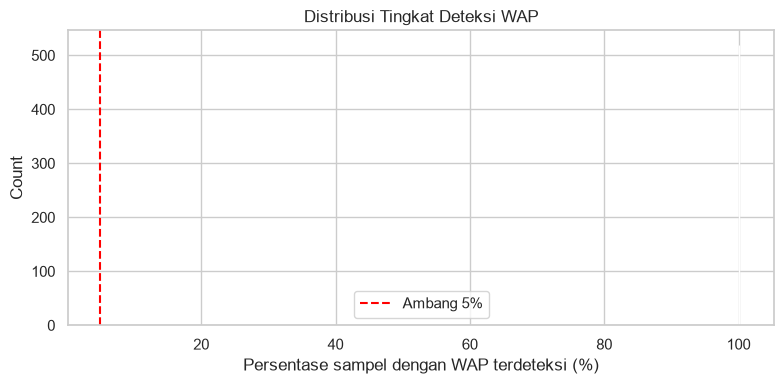

In [40]:
# Hitung deteksi dari data asli, sebelum penggantian nilai 100
detection_rate = (
    df_train[WAP_COLS].ne(100).mean() * 100
).sort_values()

display(detection_rate.describe())

plt.figure(figsize=(8, 4))
sns.histplot(detection_rate, bins=30)
plt.axvline(5, color="red", linestyle="--", label="Ambang 5%")
plt.xlabel("Persentase sampel dengan WAP terdeteksi (%)")
plt.title("Distribusi Tingkat Deteksi WAP")
plt.legend()
plt.tight_layout()
plt.show()

In [41]:
# Target klasifikasi
y_class = df_train[TARGET_CLASS].copy()

# Target regresi
y_reg = df_train[TARGET_REG].copy()

# Fitur RSSI saja, tanpa metadata dan target
X = df_train[WAP_COLS].copy()

# Split 80:20
X_train_80, X_test_80, y_class_train_80, y_class_test_80 = train_test_split(
    X, y_class,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_class["BUILDINGID"]
)

# Split 70:30
X_train_70, X_test_70, y_class_train_70, y_class_test_70 = train_test_split(
    X, y_class,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y_class["BUILDINGID"]
)

print("Split 80:20:", X_train_80.shape, X_test_80.shape)
print("Split 70:30:", X_train_70.shape, X_test_70.shape)

Split 80:20: (15949, 520) (3988, 520)
Split 70:30: (13955, 520) (5982, 520)


In [42]:
THRESHOLD = 5  # Persentase minimum deteksi

def select_wap_features(X_train, X_test, threshold=5):
    # Nilai -105 menunjukkan WAP tidak terdeteksi
    detection = (X_train > -105).mean() * 100

    selected = detection[detection >= threshold].index.tolist()

    return X_train[selected], X_test[selected], selected


# Seleksi untuk split 80:20
X_train_80_sel, X_test_80_sel, selected_80 = select_wap_features(
    X_train_80, X_test_80, THRESHOLD
)

# Seleksi untuk split 70:30
X_train_70_sel, X_test_70_sel, selected_70 = select_wap_features(
    X_train_70, X_test_70, THRESHOLD
)

print("Fitur awal:", len(WAP_COLS))
print("Fitur terpilih split 80:20:", len(selected_80))
print("Fitur terpilih split 70:30:", len(selected_70))

Fitur awal: 520
Fitur terpilih split 80:20: 114
Fitur terpilih split 70:30: 114


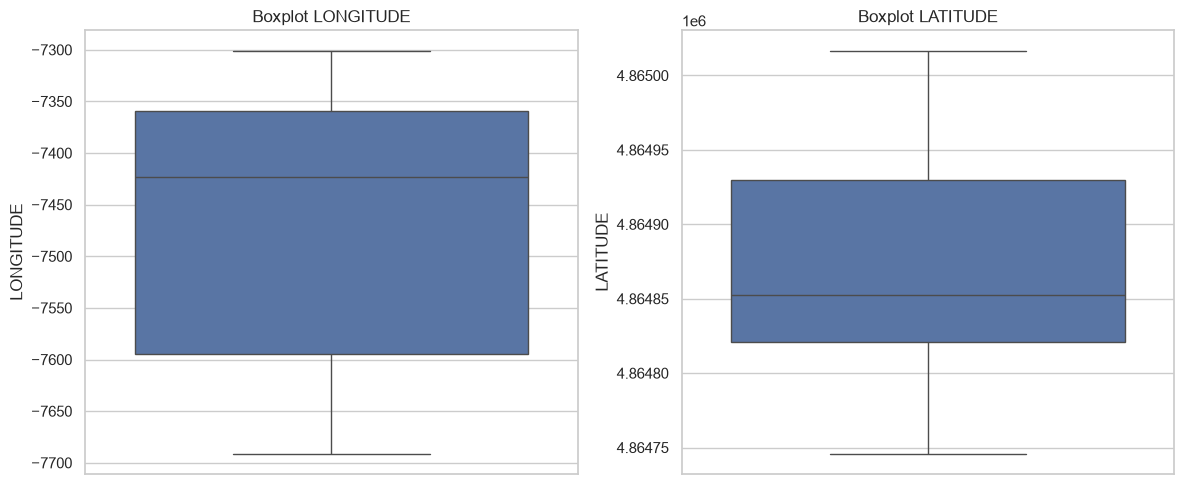

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df_train["LONGITUDE"], ax=axes[0])
axes[0].set_title("Boxplot LONGITUDE")

sns.boxplot(y=df_train["LATITUDE"], ax=axes[1])
axes[1].set_title("Boxplot LATITUDE")

plt.tight_layout()
plt.show()

In [45]:
OUTPUT_DIR = Path("data")
OUTPUT_DIR.mkdir(exist_ok=True)

df_train.to_csv(
    OUTPUT_DIR / "trainingData_cleaned.csv",
    index=False
)

df_valid.to_csv(
    OUTPUT_DIR / "validationData_cleaned.csv",
    index=False
)

print("Dataset dan daftar fitur berhasil disimpan.")

Dataset dan daftar fitur berhasil disimpan.


# Model 

In [46]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif, f_regression

from sklearn.model_selection import (
    train_test_split, cross_val_score, StratifiedKFold, KFold
)

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)

from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC, SVR
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    GradientBoostingClassifier,
    RandomForestRegressor, ExtraTreesRegressor,
    GradientBoostingRegressor
)
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.multioutput import MultiOutputRegressor

from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score,
    adjusted_rand_score, normalized_mutual_info_score
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

In [48]:
df = pd.read_csv("data/trainingData_cleaned.csv")

WAP_COLS = sorted(
    [c for c in df.columns if c.startswith("WAP")],
    key=lambda c: int(c.replace("WAP", ""))
)

X = df[WAP_COLS].copy()

targets_class = ["BUILDINGID", "FLOOR"]
targets_reg = ["LONGITUDE", "LATITUDE"]

print("Jumlah sampel:", len(df))
print("Jumlah fitur WAP:", len(WAP_COLS))
print("Target klasifikasi:", targets_class)
print("Target regresi:", targets_reg)

Jumlah sampel: 19937
Jumlah fitur WAP: 520
Target klasifikasi: ['BUILDINGID', 'FLOOR']
Target regresi: ['LONGITUDE', 'LATITUDE']


In [49]:
classification_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=RANDOM_STATE
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(probability=True, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    )
}

mlp_class_configs = {
    "MLP 64": (64,),
    "MLP 128-64": (128, 64),
    "MLP 128-64-32": (128, 64, 32)
}

def make_classification_pipeline(model, k=100):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("selection", SelectKBest(score_func=f_classif, k=min(k, len(WAP_COLS)))),
        ("model", clone(model))
    ])

In [50]:
classification_results = []
classification_predictions = {}

for target in targets_class:
    y = df[target]

    for test_size in [0.20, 0.30]:
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y,
            test_size=test_size,
            random_state=RANDOM_STATE,
            stratify=y
        )

        min_class_count = y_tr.value_counts().min()
        cv_folds = min(5, int(min_class_count))

        if cv_folds < 2:
            print(f"Skip CV: kelas terlalu sedikit untuk {target}")
            continue

        cv = StratifiedKFold(
            n_splits=cv_folds,
            shuffle=True,
            random_state=RANDOM_STATE
        )

        models = dict(classification_models)

        for name, layers in mlp_class_configs.items():
            models[name] = MLPClassifier(
                hidden_layer_sizes=layers,
                max_iter=300,
                early_stopping=True,
                random_state=RANDOM_STATE
            )

        for name, model in models.items():
            pipe = make_classification_pipeline(model)

            cv_scores = cross_val_score(
                pipe, X_tr, y_tr,
                cv=cv, scoring="f1_macro", n_jobs=-1
            )

            start = time.time()
            pipe.fit(X_tr, y_tr)
            train_seconds = time.time() - start

            pred = pipe.predict(X_te)

            classification_results.append({
                "Target": target,
                "Split": f"{int((1-test_size)*100)}:{int(test_size*100)}",
                "Model": name,
                "Accuracy": accuracy_score(y_te, pred),
                "Precision_macro": precision_score(
                    y_te, pred, average="macro", zero_division=0
                ),
                "Recall_macro": recall_score(
                    y_te, pred, average="macro", zero_division=0
                ),
                "F1_macro": f1_score(
                    y_te, pred, average="macro", zero_division=0
                ),
                "CV_F1_mean": cv_scores.mean(),
                "CV_F1_std": cv_scores.std(),
                "Training_seconds": train_seconds,
                "Parameters": pipe.named_steps["model"].get_params()
            })

            classification_predictions[(target, test_size, name)] = (
                pipe, X_te, y_te, pred
            )

classification_results = pd.DataFrame(classification_results)

display(
    classification_results.sort_values(
        ["Target", "Split", "F1_macro"],
        ascending=[True, True, False]
    )
)

,Target,Split,Model,Accuracy,Precision_macro,Recall_macro,F1_macro,CV_F1_mean,CV_F1_std,Training_seconds,Parameters
13,BUILDINGID,70:30,Extra Trees,0.998495,0.998087,0.998947,0.998513,0.996444,0.001213,0.825770,"{'bootstrap': False, 'ccp_alpha': 0.0, 'class_..."
12,BUILDINGID,70:30,Random Forest,0.998161,0.997663,0.998521,0.998088,0.996657,0.001350,0.799396,"{'bootstrap': True, 'ccp_alpha': 0.0, 'class_w..."
15,BUILDINGID,70:30,MLP 64,0.997660,0.997308,0.997977,0.997640,0.993424,0.002457,2.669584,"{'activation': 'relu', 'alpha': 0.0001, 'batch..."
17,BUILDINGID,70:30,MLP 128-64-32,0.997492,0.996823,0.998150,0.997477,0.995537,0.001517,2.787518,"{'activation': 'relu', 'alpha': 0.0001, 'batch..."
9,BUILDINGID,70:30,Logistic Regression,0.996991,0.996374,0.997605,0.996981,0.994501,0.001711,0.674680,"{'C': 1.0, 'class_weight': None, 'dual': False..."
10,BUILDINGID,70:30,KNN,0.996824,0.996067,0.997391,0.996721,0.993810,0.001673,0.578736,"{'algorithm': 'auto', 'leaf_size': 30, 'metric..."
14,BUILDINGID,70:30,Gradient Boosting,0.996657,0.996135,0.996988,0.996556,0.994555,0.001783,11.176209,"{'ccp_alpha': 0.0, 'criterion': 'deprecated', ..."
16,BUILDINGID,70:30,MLP 128-64,0.996489,0.995925,0.997060,0.996486,0.994790,0.001690,2.205098,"{'activation': 'relu', 'alpha': 0.0001, 'batch..."
11,BUILDINGID,70:30,SVM,0.995654,0.994958,0.996185,0.995565,0.993149,0.002425,4.029018,"{'C': 1.0, 'break_ties': False, 'cache_size': ..."
3,BUILDINGID,80:20,Random Forest,0.998495,0.998086,0.998947,0.998513,0.996789,0.000347,0.940212,"{'bootstrap': True, 'ccp_alpha': 0.0, 'class_w..."



Target: BUILDINGID | Split: 80:20
Model terbaik: Random Forest
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1050
           1       0.99      1.00      1.00      1039
           2       1.00      1.00      1.00      1899

    accuracy                           1.00      3988
   macro avg       1.00      1.00      1.00      3988
weighted avg       1.00      1.00      1.00      3988



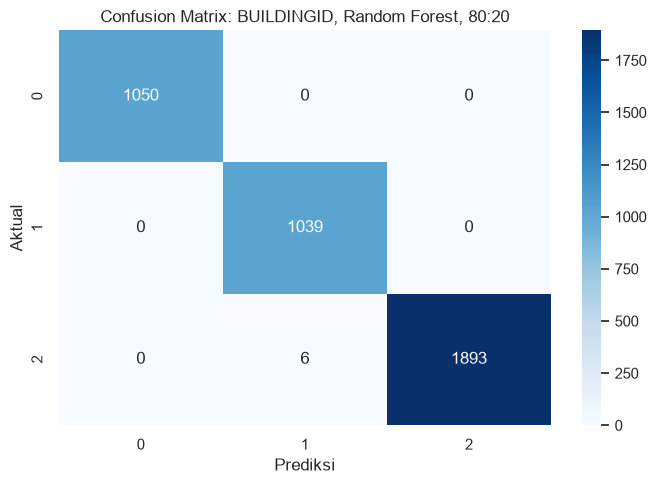


Target: BUILDINGID | Split: 70:30
Model terbaik: Extra Trees
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1575
           1       0.99      1.00      1.00      1559
           2       1.00      1.00      1.00      2848

    accuracy                           1.00      5982
   macro avg       1.00      1.00      1.00      5982
weighted avg       1.00      1.00      1.00      5982



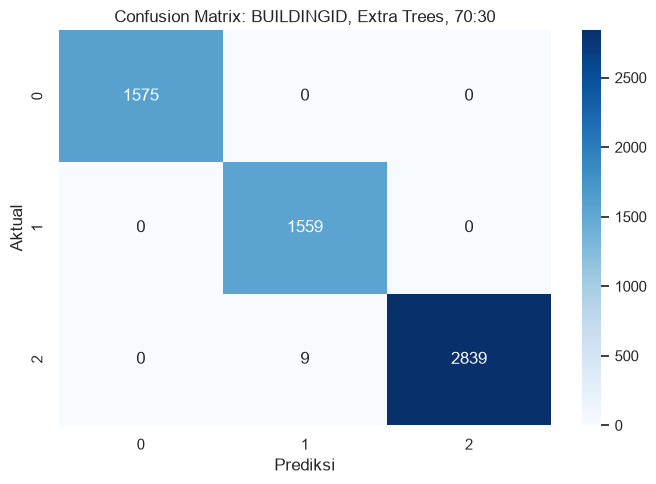


Target: FLOOR | Split: 80:20
Model terbaik: Random Forest
              precision    recall  f1-score   support

           0       0.95      0.92      0.93       874
           1       0.93      0.91      0.92      1001
           2       0.91      0.80      0.85       883
           3       0.83      0.96      0.89      1010
           4       1.00      1.00      1.00       220

    accuracy                           0.90      3988
   macro avg       0.92      0.92      0.92      3988
weighted avg       0.91      0.90      0.90      3988



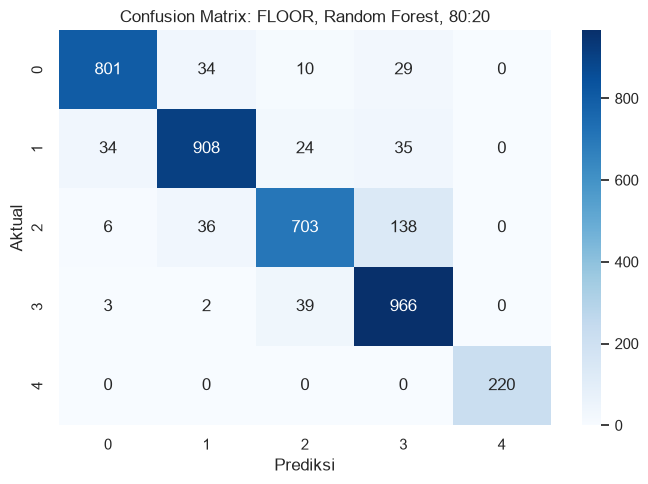


Target: FLOOR | Split: 70:30
Model terbaik: Random Forest
              precision    recall  f1-score   support

           0       0.94      0.91      0.93      1311
           1       0.92      0.91      0.91      1501
           2       0.91      0.80      0.85      1325
           3       0.83      0.95      0.88      1514
           4       1.00      1.00      1.00       331

    accuracy                           0.90      5982
   macro avg       0.92      0.91      0.91      5982
weighted avg       0.90      0.90      0.90      5982



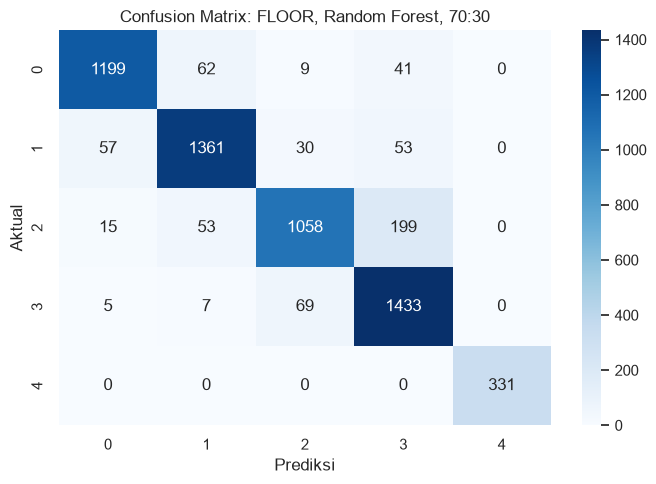

In [51]:
for target in targets_class:
    for test_size in [0.20, 0.30]:
        split_name = f"{int((1-test_size)*100)}:{int(test_size*100)}"

        subset = classification_results[
            (classification_results["Target"] == target) &
            (classification_results["Split"] == split_name)
        ]

        if subset.empty:
            continue

        best_name = subset.loc[subset["F1_macro"].idxmax(), "Model"]

        pipe, X_te, y_te, pred = classification_predictions[
            (target, test_size, best_name)
        ]

        print(f"\nTarget: {target} | Split: {split_name}")
        print("Model terbaik:", best_name)
        print(classification_report(y_te, pred, zero_division=0))

        labels = sorted(pd.unique(pd.concat([y_te, pd.Series(pred)])))

        cm = confusion_matrix(y_te, pred, labels=labels)

        plt.figure(figsize=(7, 5))
        sns.heatmap(
            cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels
        )
        plt.title(f"Confusion Matrix: {target}, {best_name}, {split_name}")
        plt.xlabel("Prediksi")
        plt.ylabel("Aktual")
        plt.tight_layout()
        plt.show()

In [52]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay

for target in targets_class:
    for test_size in [0.20, 0.30]:
        subset = classification_results[
            (classification_results["Target"] == target) &
            (classification_results["Split"] ==
             f"{int((1-test_size)*100)}:{int(test_size*100)}")
        ]

        if subset.empty or df[target].nunique() != 2:
            continue

        best_name = subset.loc[subset["F1_macro"].idxmax(), "Model"]
        pipe, X_te, y_te, pred = classification_predictions[
            (target, test_size, best_name)
        ]

        probabilities = pipe.predict_proba(X_te)[:, 1]
        auc = roc_auc_score(y_te, probabilities)

        print(f"{target} | {best_name} | ROC AUC = {auc:.4f}")

        RocCurveDisplay.from_predictions(y_te, probabilities)
        plt.title(f"ROC Curve: {target} - {best_name}")
        plt.tight_layout()
        plt.show()

In [53]:
regression_models = {
    "Ridge": Ridge(),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "SVR": MultiOutputRegressor(SVR()),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": MultiOutputRegressor(
        GradientBoostingRegressor(random_state=RANDOM_STATE)
    )
}

mlp_reg_configs = {
    "MLP 64": (64,),
    "MLP 128-64": (128, 64),
    "MLP 128-64-32": (128, 64, 32)
}

def make_regression_pipeline(model, k=100):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("selection", SelectKBest(score_func=f_regression, k=min(k, len(WAP_COLS)))),
        ("model", clone(model))
    ])

In [54]:
regression_results = []
regression_predictions = {}

for target in targets_reg:
    y = df[target]

    for test_size in [0.20, 0.30]:
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y,
            test_size=test_size,
            random_state=RANDOM_STATE
        )

        cv = KFold(
            n_splits=5,
            shuffle=True,
            random_state=RANDOM_STATE
        )

        models = dict(regression_models)

        for name, layers in mlp_reg_configs.items():
            models[name] = MLPRegressor(
                hidden_layer_sizes=layers,
                max_iter=300,
                early_stopping=True,
                random_state=RANDOM_STATE
            )

        for name, model in models.items():
            pipe = make_regression_pipeline(model)

            cv_scores = cross_val_score(
                pipe, X_tr, y_tr,
                cv=cv,
                scoring="neg_mean_absolute_error",
                n_jobs=-1
            )

            start = time.time()
            pipe.fit(X_tr, y_tr)
            train_seconds = time.time() - start

            pred = pipe.predict(X_te)

            regression_results.append({
                "Target": target,
                "Split": f"{int((1-test_size)*100)}:{int(test_size*100)}",
                "Model": name,
                "MAE": mean_absolute_error(y_te, pred),
                "RMSE": np.sqrt(mean_squared_error(y_te, pred)),
                "R2": r2_score(y_te, pred),
                "CV_MAE_mean": -cv_scores.mean(),
                "CV_MAE_std": cv_scores.std(),
                "Training_seconds": train_seconds,
                "Parameters": pipe.named_steps["model"].get_params()
            })

            regression_predictions[(target, test_size, name)] = (
                pipe, X_te, y_te, pred
            )

regression_results = pd.DataFrame(regression_results)

display(
    regression_results.sort_values(
        ["Target", "Split", "MAE"]
    )
)

ValueError: 
All the 5 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "d:\DATA\S2\Semester 1\Deep Learning\mini project\.venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 860, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "d:\DATA\S2\Semester 1\Deep Learning\mini project\.venv\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "d:\DATA\S2\Semester 1\Deep Learning\mini project\.venv\Lib\site-packages\sklearn\pipeline.py", line 645, in fit
    self._final_estimator.fit(Xt, y, **last_step_params["fit"])
    ~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^

In [ ]:
for target in targets_reg:
    for test_size in [0.20, 0.30]:
        split_name = f"{int((1-test_size)*100)}:{int(test_size*100)}"

        subset = regression_results[
            (regression_results["Target"] == target) &
            (regression_results["Split"] == split_name)
        ]

        best_name = subset.loc[subset["MAE"].idxmin(), "Model"]

        pipe, X_te, y_te, pred = regression_predictions[
            (target, test_size, best_name)
        ]

        residual = np.asarray(y_te) - np.asarray(pred)

        # Prediksi vs aktual
        plt.figure(figsize=(6, 5))
        plt.scatter(y_te, pred, alpha=0.5)

        low = min(np.min(y_te), np.min(pred))
        high = max(np.max(y_te), np.max(pred))
        plt.plot([low, high], [low, high], "r--")

        plt.xlabel(f"Aktual {target}")
        plt.ylabel(f"Prediksi {target}")
        plt.title(f"{target}: Prediksi vs Aktual ({best_name})")
        plt.tight_layout()
        plt.show()

        # Residual plot
        plt.figure(figsize=(6, 5))
        plt.scatter(pred, residual, alpha=0.5)
        plt.axhline(0, color="red", linestyle="--")

        plt.xlabel(f"Prediksi {target}")
        plt.ylabel("Residual")
        plt.title(f"Residual Plot: {target} ({best_name})")
        plt.tight_layout()
        plt.show()

In [ ]:
for test_size in [0.20, 0.30]:
    best_models = {}

    for target in targets_reg:
        subset = regression_results[
            (regression_results["Target"] == target) &
            (regression_results["Split"] ==
             f"{int((1-test_size)*100)}:{int(test_size*100)}")
        ]

        best_models[target] = subset.loc[
            subset["MAE"].idxmin(), "Model"
        ]

    _, _, y_lon, pred_lon = regression_predictions[
        ("LONGITUDE", test_size, best_models["LONGITUDE"])
    ]

    _, _, y_lat, pred_lat = regression_predictions[
        ("LATITUDE", test_size, best_models["LATITUDE"])
    ]

    # Karena split random_state sama, indeks test kedua target selaras
    assert y_lon.index.equals(y_lat.index)

    actual_lon = np.asarray(y_lon)
    actual_lat = np.asarray(y_lat)
    predicted_lon = np.asarray(pred_lon)
    predicted_lat = np.asarray(pred_lat)

    position_error = np.sqrt(
        (actual_lon - predicted_lon) ** 2 +
        (actual_lat - predicted_lat) ** 2
    )

    print(f"Split {int((1-test_size)*100)}:{int(test_size*100)}")
    print("Galat posisi rata-rata (satuan koordinat):",
          round(position_error.mean(), 4))

In [ ]:
def count_mlp_parameters(mlp):
    return sum(w.size for w in mlp.coefs_) + sum(
        b.size for b in mlp.intercepts_
    )

for key, (pipe, X_te, y_te, pred) in classification_predictions.items():
    target, test_size, model_name = key

    if not model_name.startswith("MLP"):
        continue

    mlp = pipe.named_steps["model"]

    print(
        target, model_name,
        "| Parameter:", count_mlp_parameters(mlp),
        "| Iterasi:", mlp.n_iter_
    )

    plt.figure(figsize=(7, 4))
    plt.plot(mlp.loss_curve_, label="Training loss")

    if hasattr(mlp, "validation_scores_") and mlp.validation_scores_ is not None:
        plt.twinx()
        plt.plot(
            mlp.validation_scores_,
            color="orange",
            label="Validation accuracy"
        )
        plt.ylabel("Validation accuracy")

    plt.title(f"Kurva MLP: {target}, {model_name}")
    plt.xlabel("Iterasi")
    plt.tight_layout()
    plt.show()

In [ ]:
# Clustering menggunakan data training
X_cluster = X.copy()

# Preprocessing untuk clustering
cluster_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_scaled = cluster_pipe.fit_transform(X_cluster)

# PCA untuk visualisasi 2D
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

# Elbow
inertias = []

for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(2, 11), inertias, marker="o")
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.tight_layout()
plt.show()

In [ ]:
rng = np.random.RandomState(RANDOM_STATE)

if len(X_scaled) > 5000:
    idx = rng.choice(len(X_scaled), 5000, replace=False)
else:
    idx = np.arange(len(X_scaled))

X_sample = X_scaled[idx]
y_sample = df.iloc[idx]["BUILDINGID"].to_numpy()

# K-Means
kmeans = KMeans(n_clusters=df["BUILDINGID"].nunique(),
                random_state=RANDOM_STATE, n_init=10)
labels_km = kmeans.fit_predict(X_sample)

# DBSCAN
dbscan = DBSCAN(eps=5, min_samples=5)
labels_db = dbscan.fit_predict(X_sample)

def clustering_metrics(X_data, predicted, true_labels):
    mask = predicted != -1
    clusters = np.unique(predicted[mask])

    if mask.sum() > 1 and len(clusters) > 1:
        silhouette = silhouette_score(X_data[mask], predicted[mask])
        db_index = davies_bouldin_score(X_data[mask], predicted[mask])
    else:
        silhouette, db_index = np.nan, np.nan

    return {
        "Silhouette": silhouette,
        "Davies_Bouldin": db_index,
        "ARI": adjusted_rand_score(true_labels, predicted),
        "NMI": normalized_mutual_info_score(true_labels, predicted)
    }

cluster_results = pd.DataFrame([
    {
        "Model": "K-Means",
        **clustering_metrics(X_sample, labels_km, y_sample)
    },
    {
        "Model": "DBSCAN",
        **clustering_metrics(X_sample, labels_db, y_sample)
    }
])

display(cluster_results)

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(
    X_pca[idx, 0], X_pca[idx, 1],
    c=labels_km, cmap="tab10", s=10, alpha=0.7
)
plt.title("PCA 2D: Hasil K-Means")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

In [ ]:
OUTPUT_DIR = Path("hasil_modeling")
OUTPUT_DIR.mkdir(exist_ok=True)

classification_results.drop(
    columns=["Parameters"]
).to_csv(
    OUTPUT_DIR / "hasil_klasifikasi.csv",
    index=False
)

regression_results.drop(
    columns=["Parameters"]
).to_csv(
    OUTPUT_DIR / "hasil_regresi.csv",
    index=False
)

cluster_results.to_csv(
    OUTPUT_DIR / "hasil_clustering.csv",
    index=False
)

print("Semua hasil eksperimen disimpan di:", OUTPUT_DIR.resolve())